# Fitting different signals to observed photonic lantern spectra

In [65]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Defining constants

In [66]:
# Constants
MAS_TO_RAD = 1e-3/206265 # [rad/mas]

# Photonic lantern attributes
N_DIM = 65 # Number of pixels in pupil grid
DIAMETER = 10 # [m], diameter of telescope aperture for pupil
FOCAL_RESOLUTION = 1e-6 # [m], resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
FOCAL_LENGTH = 40 # [m], focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)

# Fiber attributes
N_CORE = 1.444 # Index of refraction of the core
N_CLAD = 1.444 - 5.5e-3 # Index of refraction of the cladding
R_CORE = 10e-6 # [m], core radius

# Wavelengths
N_SPEC = 150 # Number of wavelength channels
WAV_MIDDLE = 1282.8 # [nm], Paschen beta line
WAV_WIDTH = 0.1 # [nm]
WAV_BANDWIDTH = 10*WAV_WIDTH # [nm]
WAV_RANGE = np.linspace(WAV_MIDDLE - WAV_BANDWIDTH/2, WAV_MIDDLE + WAV_BANDWIDTH/2, N_SPEC)

## Creating the photonic lantern model

In [67]:
photonic_lantern_device = PhotonicLanternDevice(
    N_DIM=N_DIM,
    DIAMETER=DIAMETER,
    FOCAL_RESOLUTION=FOCAL_RESOLUTION,
    WAV_MIDDLE=WAV_MIDDLE,
    N_CORE=N_CORE,
    N_CLAD=N_CLAD,
    R_CORE=R_CORE,
    FOCAL_LENGTH=FOCAL_LENGTH,
    N_SPEC=N_SPEC
)

Created pupil grid
Created focal grid

Fiber details:
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05 m
ref_wavelength: 1.2828e-06 m

Created aperture
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b']
Number of modes:  10
Created optical transfer function

Computed optical transfer function

Generated unitary matrix of shape: (N_SPEC x N_OUTPUTS x N_OUTPUTS) -> (150, 10, 10)

Device initialized with:
  Lantern matrices: (150, 10, 10)
  PIC matrices: None
  Wavelengths: 150
Initialized device with the unitary matrix

Defined scene
Projected scene onto optical transfer function



## Creating spectra of the two stars

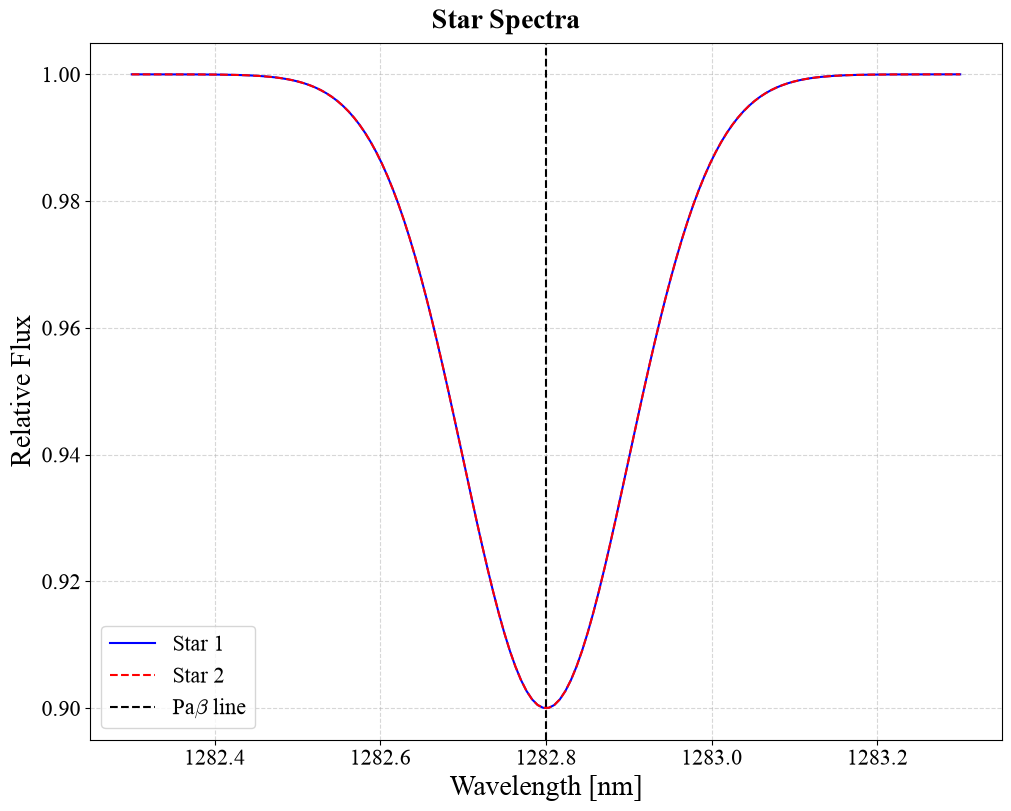

In [68]:
# Mass of the stars
M_1 = 1 # [M_1]
M_2 = 1 # [M_1]

# Flux of the continuum of the stars
F_1 = 1
F_2 = F_1 / functions.M_L_relation(M_1, M_2)

# Depth of the line
A_LINE_1 = 0.9
A_LINE_2 = 0.9

# Middle wavelength of each absorption line
WAV_MIDDLE_1 = WAV_MIDDLE
WAV_MIDDLE_2 = WAV_MIDDLE

# Width of each absorption line
WAV_WIDTH_1 = WAV_WIDTH
WAV_WIDTH_2 = WAV_WIDTH

# Spectrum of star 1
star1_spectrum = functions.create_spectrum(F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1, WAV_RANGE)

# Spectrum of star 2
star2_spectrum = functions.create_spectrum(F_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2, WAV_RANGE)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(WAV_RANGE, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

## Passing stars into the photonic lantern device

Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> (150, 10)


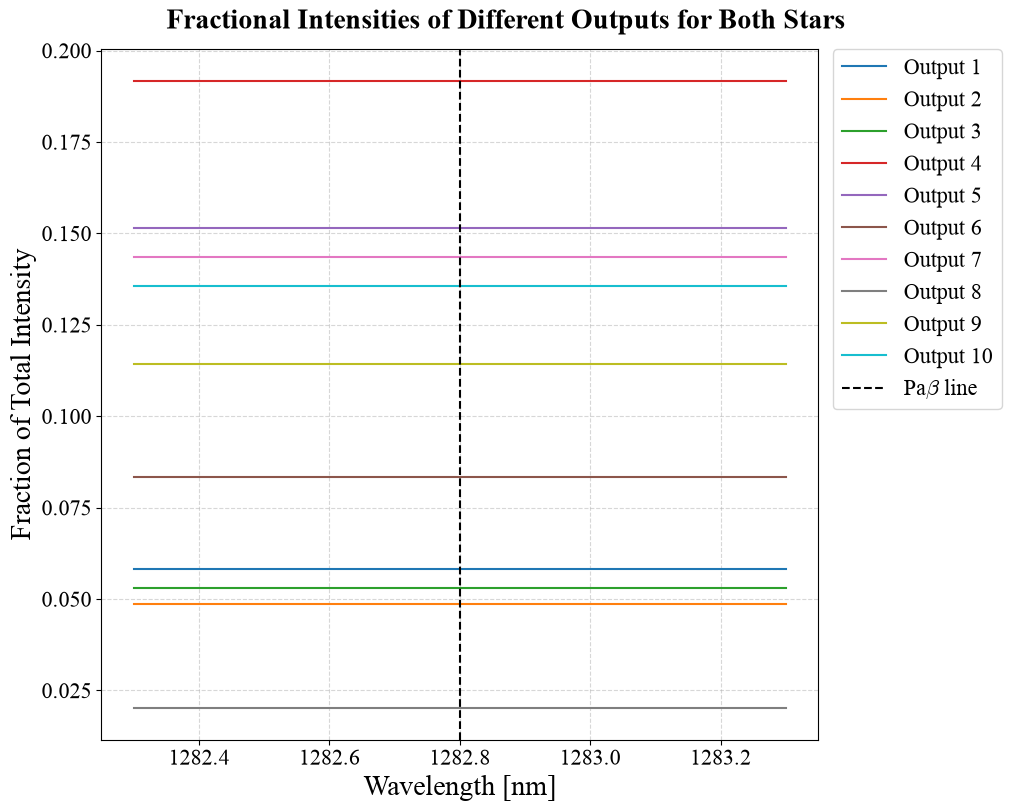

In [69]:
# Star 1 position
star1_x = 0
star1_y = 0
star1_position = np.array([star1_x, star1_y])

# Star 2 position
star2_x = 30
star2_y = 0
star2_position = np.array([star2_x, star2_y])

# Calculating photonic lantern outputs
combined_outputs = photonic_lantern_device.calculate_photonic_lantern_outputs(np.array([star1_position, star2_position]), np.array([star1_spectrum, star2_spectrum]))

# Computing the total intensities across all outputs as a function of wavelength
total_intensity = np.sum(combined_outputs, axis=1)

# Computing fractional intensities for the outputs
fractional_intensity = combined_outputs / total_intensity.reshape(-1, 1)

print(f'Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> {fractional_intensity.shape}')

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Fractional Intensities of Different Outputs for Both Stars')

for i in range(photonic_lantern_device.N_PORTS):
    ax.plot(WAV_RANGE, fractional_intensity[:, i], label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Fraction of Total Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()